# Этап 2 (событие — заключение) · 03. Дополнения к основной модели: раса, взаимодействия узлов, вероятности переходов графа

**Место в цепочке.** 01 → 02 → **03**. Ноутбук читает таблицу `out/free_episodes_features.csv` из ноутбука 01 и сравнивает дополнения с **итоговой моделью ноутбука 02**: все семейства A–G с F2, включая расу, три цели — любой возврат в заключение и причинно-специфические модели для нового и старого дела. Результаты кросс-валидаций базовых наборов берутся из кэша ноутбука 02 (`out/_cv_cache`), так что числа совпадают с 02.

Проверяются три дополнения:

1. **Раса подробно.** В 02 раса — семейство G. Здесь: (а) объясняются ли расовые различия во времени до возврата историей человека, (б) что раса добавляет к прогнозу, (в) одинаково ли хорошо модель работает для разных групп.
2. **Взаимодействия «предыдущее состояние × текущее».** История по графу (семейство E) добавляет мало. Гипотеза: линейная модель не видит сочетаний — «был Drug, теперь Property» может значить не то же самое, что сумма «был Drug» и «теперь Property».
3. **Вероятности переходов графа (марковская цепь).** Граф этапа 1 — это матрица переходов между состояниями. Из неё можно получить признаки: какой следующий узел типичен для текущего состояния, насколько «обычен» путь человека.

Схема та же, что в 02: модель Кокса с гребневым штрафом, 5 фолдов с разбиением по людям, прирост C-индекса **парно** к полной модели (те же фолды) — так видно, что добавляет дополнение *сверх уже имеющегося*. Для причин — C Харрелла причинно-специфических моделей. Код — `stage2_extra.py`.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time
import stage2_features as sf, stage2_models as sm, stage2_extra as sx
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
t_start = time.time()
ds = pd.read_csv('out/free_episodes_features.csv', parse_dates=['t0'])
fam = sf.family_columns(ds); RACE = fam['G раса']
RFM = fam['A база'] + fam['B RFM']; ALL = [c for k in fam for c in fam[k]]; ALL_NORACE = [c for c in ALL if c not in RACE]
T, E, C = ds.time_custody.values.astype(float), ds.event_custody.values.astype(int), ds.cause.values
nodes, spells, arrests = sx.load_parts()
USE_CACHE = True   # False - пересчитать кросс-валидации заново
memo = sx.make_memo(ds, USE_CACHE)
print(f'эпизодов: {len(ds)}, людей: {ds.person_id.nunique()}, возвратов: {E.sum()} ({E.mean():.1%}) | признаков в полной модели: {len(ALL)}')

эпизодов: 21597, людей: 10917, возвратов: 11304 (52.3%) | признаков в полной модели: 129


In [2]:
RESULTS = {}
def compare(name, any_res, cr_res, ref='ALL'):
    '''Прирост C-индекса парно (те же фолды) к базовой модели ref: любой возврат, новое дело, старое дело.'''
    ra, rc = any_res, cr_res; ba, bc = BASE[ref]
    row = {'C любой': ra.c_index.mean()}
    for nm, d in [('любой', ra.c_index - ba.c_index), ('новое', rc.C_new - bc.C_new), ('старое', rc.C_old - bc.C_old)]:
        row[f'ΔC {nm}'] = d.mean(); row[f'sd {nm}'] = d.std(ddof=1)
    row['к чему'] = ref; RESULTS[name] = row
    return pd.Series(row)
def table():
    t = pd.DataFrame(RESULTS).T
    return t.astype({c: float for c in t.columns if c != 'к чему'}).round(4)
BASE = {}
for nm, cols in {'RFM': RFM, 'ALL': ALL}.items():
    BASE[nm] = (memo(sm.cv_cox, cols)[0], memo(sx.cv_competing, cols)[0])
oof_all = memo(sm.cv_cox, ALL)[1]
pd.DataFrame({nm: {'C любой': a.c_index.mean(), 'C новое': c.C_new.mean(), 'C старое': c.C_old.mean()} for nm, (a, c) in BASE.items()}).T.round(4)

,C любой,C новое,C старое
RFM,0.6457,0.6598,0.6718
ALL,0.6868,0.7278,0.7100


## 1. Раса

### 1.1. Почему раса в модели

Сначала раса была исключена: вокруг COMPAS идёт спор о расовой несправедливости (ProPublica, 2016), модель с расой сложнее защищать. Но без расы нельзя проверить, *объясняются ли* расовые различия во времени до возврата историей человека, и нельзя проверить, одинаково ли модель работает для разных групп. В основной модели (02) раса — семейство G: три индикатора, опорная группа Caucasian; Asian (58 человек) и Native American (40) объединены с Other.

,группа,людей,эпизодов,доля эпизодов,P(любой возврат ≤ 365),CIF новое (365),CIF старое (365),среднее число прошлых арестов
0,AfricanAmerican,5358,11686,0.541,0.512,0.310,0.154,7.824
1,Caucasian,3847,7155,0.331,0.424,0.252,0.137,5.051
2,Hispanic,990,1586,0.073,0.334,0.207,0.101,3.646
3,Other,722,1170,0.054,0.335,0.212,0.092,3.718


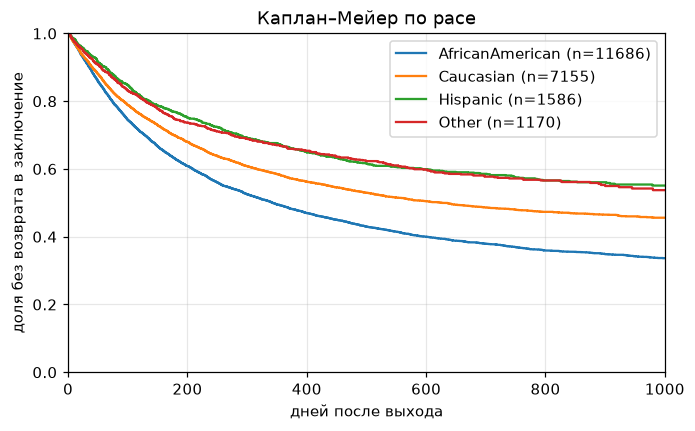

In [3]:
rows = []
for g in ['AfricanAmerican', 'Caucasian', 'Hispanic', 'Other']:
    mk = ds.race4.values == g; tk, sk = sm.km(T[mk], E[mk]); tg_, aj_, _ = sx.aalen_johansen(T[mk], C[mk])
    rows.append({'группа': g, 'людей': ds.person_id[mk].nunique(), 'эпизодов': int(mk.sum()), 'доля эпизодов': mk.mean(),
                 'P(любой возврат ≤ 365)': 1 - float(sm.km_at(tk, sk, 365)), 'CIF новое (365)': float(sm.km_at(tg_, aj_[1], 365)),
                 'CIF старое (365)': float(sm.km_at(tg_, aj_[2], 365)), 'среднее число прошлых арестов': ds.h_n_prior_arrests[mk].mean()})
race_desc = pd.DataFrame(rows).round(3); race_desc.to_csv('out/race_descriptive.csv', index=False); display(race_desc)
fig, ax = plt.subplots(figsize=(7, 4))
for g in ['AfricanAmerican', 'Caucasian', 'Hispanic', 'Other']:
    mk = ds.race4.values == g; tk, sk = sm.km(T[mk], E[mk]); ax.step(tk, sk, where='post', label=f'{g} (n={mk.sum()})')
ax.set_xlim(0, 1000); ax.set_ylim(0, 1); ax.set_xlabel('дней после выхода'); ax.set_ylabel('доля без возврата в заключение'); ax.grid(alpha=.3); ax.legend()
ax.set_title('Каплан–Мейер по расе'); plt.savefig('out/km_by_race.png', dpi=120, bbox_inches='tight'); plt.show()

### 1.2. Объясняется ли разница историей человека

Если различие между группами — следствие разной истории (у одной группы больше прошлых арестов и заключений), то после добавления истории в модель отношение рисков (HR) для расы должно приблизиться к 1. Модели строятся на всех данных; HR — для индикатора (группа против Caucasian), а не на одно стандартное отклонение. Стандартные ошибки наивные (без поправки на повторные эпизоды одного человека), поэтому интервалы немного занижены.

In [4]:
rows = []
for name, cols in {'только раса': RACE, 'возраст, пол + раса': fam['A база'] + RACE, 'RFM + раса': RFM + RACE, 'все семейства (A–G)': ALL}.items():
    prep = sm.Prep().fit(ds, cols); Xp = prep.transform(ds)
    for target, ev in [('любой', E), ('новое', (C == 1).astype(int)), ('старое', (C == 2).astype(int))]:
        m = sm.Cox(l2=0.01).fit(Xp, T, ev)
        for lv in sx.RACE_LEVELS:
            c = f'race_{lv}'; j = prep.keep.index(c); b, se = m.beta[j] / prep.sd[c], m.se[j] / prep.sd[c]
            rows.append({'модель': name, 'цель': target, 'группа (к Caucasian)': lv, 'HR': np.exp(b), 'HR 95% низ': np.exp(b - 1.96 * se), 'HR 95% верх': np.exp(b + 1.96 * se)})
race_hr = pd.DataFrame(rows).round(3); race_hr.to_csv('out/race_hr.csv', index=False)
order = ['только раса', 'возраст, пол + раса', 'RFM + раса', 'все семейства (A–G)']
race_hr.pivot_table(index='модель', columns=['цель', 'группа (к Caucasian)'], values='HR').loc[order]

цель                           любой                           новое                          старое                
группа (к Caucasian) AfricanAmerican Hispanic  Other AfricanAmerican Hispanic  Other AfricanAmerican Hispanic  Other
модель                                                                                                              
только раса                    1.323    0.748  0.762           1.350    0.759  0.826           1.202    0.709  0.632
возраст, пол + раса            1.218    0.709  0.728           1.239    0.717  0.787           1.104    0.675  0.606
RFM + раса                     1.110    0.784  0.788           1.123    0.795  0.845           1.001    0.761  0.674
все семейства (A–G)            1.016    0.822  0.856           1.019    0.843  0.930           0.987    0.801  0.731

### 1.3. Что раса добавляет к прогнозу

Сравнение полной модели с моделью без расы (A–F) и RFM с расой против RFM.

In [5]:
compare('ALL без расы (A–F)', memo(sm.cv_cox, ALL_NORACE)[0], memo(sx.cv_competing, ALL_NORACE)[0])
compare('RFM + раса', memo(sm.cv_cox, RFM + RACE)[0], memo(sx.cv_competing, RFM + RACE)[0], ref='RFM')
table()

,C любой,ΔC любой,sd любой,ΔC новое,sd новое,ΔC старое,sd старое,к чему
ALL без расы (A–F),0.6864,-0.0004,0.0005,0.0001,0.0007,-0.0009,0.0010,ALL
RFM + раса,0.6472,0.0015,0.0011,0.0007,0.0019,0.0011,0.0019,RFM


### 1.4. Одинаково ли модель работает для разных групп

Прогнозы вне обучения (out-of-fold) вероятности любого возврата за год, по группам:
- **C-индекс внутри группы** — насколько хорошо модель упорядочивает людей одной группы;
- **средний прогноз и фактическая доля** (Каплан–Мейер): отношение прогноз / факт около 1 — модель не завышает и не занижает риск группы;
- **доля в верхних 20% риска** — кого модель чаще относит к группе высокого риска.

Сравниваются модели без расы и с расой. Калибровка по группам для каждой причины — в ноутбуке 02, раздел 6.3.

In [6]:
oof_no = memo(sm.cv_cox, ALL_NORACE)[1]; rows = []
p_no, p_r = 1 - oof_no, 1 - oof_all
top_no, top_r = p_no >= np.quantile(p_no, .8), p_r >= np.quantile(p_r, .8)
for g in ['AfricanAmerican', 'Caucasian', 'Hispanic', 'Other']:
    mk = ds.race4.values == g; tk, sk = sm.km(T[mk], E[mk]); fact = 1 - float(sm.km_at(tk, sk, 365))
    for name, p, top in [('без расы', p_no, top_no), ('с расой', p_r, top_r)]:
        rows.append({'группа': g, 'модель': name, 'C внутри группы': sm.c_index(T[mk], E[mk], p[mk]), 'прогноз P(≤365)': p[mk].mean(),
                     'факт (KM)': fact, 'прогноз / факт': p[mk].mean() / fact, 'доля в верхних 20% риска': top[mk].mean()})
fair = pd.DataFrame(rows).round(3); fair.to_csv('out/race_fairness.csv', index=False); fair

,группа,модель,C внутри группы,прогноз P(≤365),факт (KM),прогноз / факт,доля в верхних 20% риска
0,AfricanAmerican,без расы,0.668,0.504,0.512,0.984,0.251
1,AfricanAmerican,с расой,0.669,0.512,0.512,0.998,0.261
2,Caucasian,без расы,0.687,0.418,0.424,0.987,0.148
3,Caucasian,с расой,0.686,0.422,0.424,0.996,0.151
4,Hispanic,без расы,0.708,0.385,0.334,1.152,0.112
5,Hispanic,с расой,0.707,0.338,0.334,1.011,0.061
6,Other,без расы,0.726,0.386,0.335,1.152,0.126
7,Other,с расой,0.724,0.349,0.335,1.041,0.079


## 2. Взаимодействия «предыдущее состояние × текущее»

### 2.1. Как построены

Состояние узла — множество из 15 типов + OldCase + Unknown; сочетаний сотни. Для взаимодействий типы укрупнены до 6 групп: **V** Violent, **P** Property, **D** Drug, **T** Traffic, **O** OldCase, **X** всё прочее (включая Unknown). Узел с несколькими типами попадает в несколько групп.

Два семейства:
- **`ix_A_B`** — предыдущий узел графа содержит группу A, текущий — группу B. Есть только у повторных эпизодов (k ≥ 2), у первых все нули.
- **`ia_A_B`** — последний арест *до текущего заключения* (вся история, `casearrest`) имеет группу A, текущий узел — группу B; A = O, если тот арест был повторным по старому делу. Это семейство обходит главное ограничение графа: у половины эпизодов предыдущего узла в окне 2013+ нет, а предыдущий арест есть у большинства.

Индикаторы, которые встречаются реже 30 раз, отброшены.

### 2.2. Есть ли эффект сочетаний в данных

Доля возвратов в заключение за год (Каплан–Мейер) для каждой пары. Если эффект чисто аддитивный, строки различаются примерно на постоянную величину, а порядок столбцов в строках одинаковый.

индикаторов ix: 36 | ia: 36


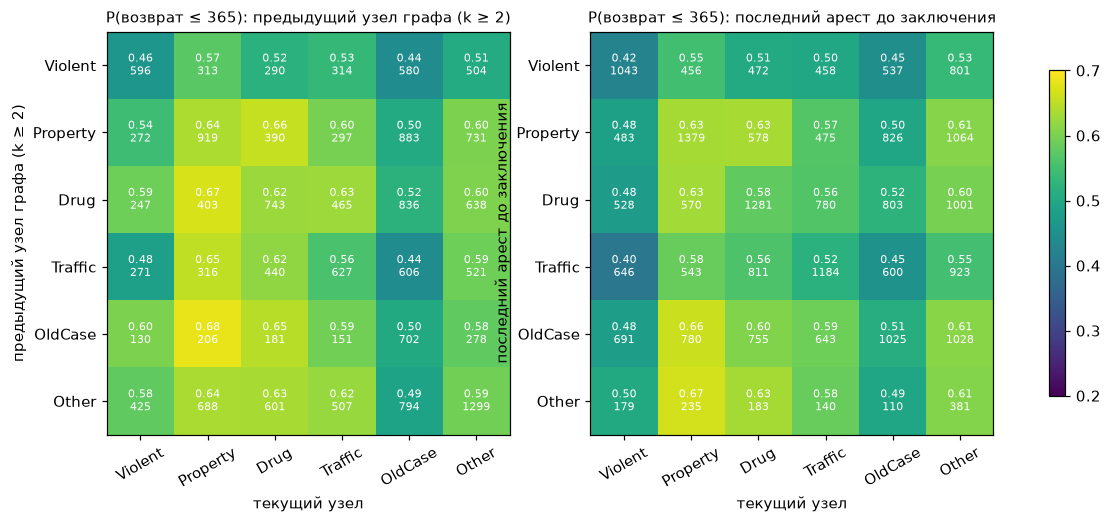

In [7]:
ix, ia = sx.interaction_features(ds, spells, arrests); IX, IA = list(ix.columns), list(ia.columns)
dsx = pd.concat([ds, ix, ia], axis=1); memo_x = sx.make_memo(dsx, USE_CACHE)     # отдельный кэш: в данных новые столбцы
print('индикаторов ix:', len(IX), '| ia:', len(IA))
def pair_matrix(prefix):
    M = pd.DataFrame(np.nan, index=sx.GROUPS, columns=sx.GROUPS); N = M.copy(); inv = {v: k for k, v in sx.SHORT.items()}
    for c in [c for c in dsx if c.startswith(prefix)]:
        a, b = c[len(prefix):].split('_'); mk = dsx[c].values == 1
        tk, sk = sm.km(T[mk], E[mk]); M.loc[inv[a], inv[b]] = 1 - float(sm.km_at(tk, sk, 365)); N.loc[inv[a], inv[b]] = mk.sum()
    return M, N
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (prefix, title) in zip(axs, [('ix_', 'предыдущий узел графа (k ≥ 2)'), ('ia_', 'последний арест до заключения')]):
    M, N = pair_matrix(prefix); im = ax.imshow(M.values.astype(float), cmap='viridis', vmin=.2, vmax=.7)
    for i in range(6):
        for j in range(6):
            if not np.isnan(M.values[i, j]): ax.text(j, i, f'{M.values[i, j]:.2f}\n{int(N.values[i, j])}', ha='center', va='center', fontsize=7, color='w')
    ax.set_xticks(range(6)); ax.set_xticklabels(sx.GROUPS, rotation=30); ax.set_yticks(range(6)); ax.set_yticklabels(sx.GROUPS)
    ax.set_xlabel('текущий узел'); ax.set_ylabel(title); ax.set_title('P(возврат ≤ 365): ' + title, fontsize=10)
plt.colorbar(im, ax=axs, shrink=.8); plt.savefig('out/interaction_heatmaps.png', dpi=120, bbox_inches='tight'); plt.show()
M_ix, N_ix = pair_matrix('ix_'); M_ix.round(3).to_csv('out/interaction_ix_return365.csv')

### 2.3. Добавляют ли взаимодействия к модели

Отдельно — C-индекс на повторных эпизодах (k ≥ 2): только у них есть `ix`.

In [8]:
t = time.time()
def cv_sub(d, cols): return sm.cv_cox(d, cols, subsets={'k2plus': d.k.values >= 2})
cv_sub.__module__ = 'nb03'
r_all_s = memo_x(cv_sub, ALL)[0]; rows = {}
for name, cols in {'ALL + ix': ALL + IX, 'ALL + ia': ALL + IA, 'ALL + ix + ia': ALL + IX + IA}.items():
    r = memo_x(cv_sub, cols)[0]; compare(name, r, memo_x(sx.cv_competing, cols)[0])
    rows[name] = {'C (k ≥ 2), любой': r.c_k2plus.mean(), 'ΔC (k ≥ 2) к ALL': (r.c_k2plus - r_all_s.c_k2plus).mean()}
print(f'время {time.time() - t:.0f} с')
display(pd.DataFrame(rows).T.round(4))
table()

время 112 с


,"C (k ≥ 2), любой",ΔC (k ≥ 2) к ALL
ALL + ix,0.6493,-0.0001
ALL + ia,0.6494,0.0000
ALL + ix + ia,0.6483,-0.0012


,C любой,ΔC любой,sd любой,ΔC новое,sd новое,ΔC старое,sd старое,к чему
ALL без расы (A–F),0.6864,-0.0004,0.0005,0.0001,0.0007,-0.0009,0.0010,ALL
RFM + раса,0.6472,0.0015,0.0011,0.0007,0.0019,0.0011,0.0019,RFM
ALL + ix,0.6869,0.0000,0.0012,0.0004,0.0015,-0.0005,0.0028,ALL
ALL + ia,0.6864,-0.0004,0.0008,-0.0005,0.0005,-0.0006,0.0014,ALL
ALL + ix + ia,0.6860,-0.0008,0.0014,-0.0005,0.0013,-0.0010,0.0030,ALL


## 3. Вероятности переходов графа (марковская цепь)

### 3.1. Матрица переходов

Узлы человека образуют последовательность; переход — пара соседних узлов. По 6 укрупнённым группам считается матрица P(следующий узел содержит B | текущий содержит A) со сглаживанием к общей частоте B (α = 5). Ниже матрица по всем данным — только для иллюстрации.

**Утечка.** Переход из текущего узла в следующий — это и есть прогнозируемое событие. Поэтому в модели матрица оценивается **заново в каждом фолде только по людям из обучающей части**, и признаки тестовых людей считаются по ней (граф пересобирается внутри кросс-валидации). В обучающей части эпизод сам участвует в оценке матрицы; групп всего 6 и в каждой тысячи переходов, так что влияние одного эпизода ничтожно, а оценка на тесте честная.

переходов в матрице: 19364 (узел с несколькими группами даёт несколько пар)


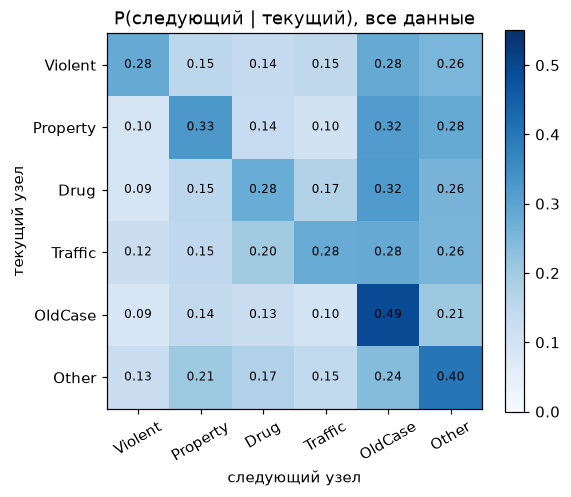

In [9]:
fold_mk, mk, by = sx.make_markov_fold_fn(ds, spells)
mk.fit(set(ds.person_id)); P = mk.P.copy(); P.round(3).to_csv('out/markov_matrix.csv')
fig, ax = plt.subplots(figsize=(5.5, 4.5)); im = ax.imshow(P.values, cmap='Blues', vmin=0, vmax=.55)
for i in range(6):
    for j in range(6): ax.text(j, i, f'{P.values[i, j]:.2f}', ha='center', va='center', fontsize=8)
ax.set_xticks(range(6)); ax.set_xticklabels(sx.GROUPS, rotation=30); ax.set_yticks(range(6)); ax.set_yticklabels(sx.GROUPS)
ax.set_xlabel('следующий узел'); ax.set_ylabel('текущий узел'); ax.set_title('P(следующий | текущий), все данные'); plt.colorbar(im)
plt.savefig('out/markov_matrix.png', dpi=120, bbox_inches='tight'); plt.show()
print('переходов в матрице:', int(mk.counts.values.sum()), '(узел с несколькими группами даёт несколько пар)')

### 3.2. Признаки

| Признак | Что это |
|---|---|
| `mk_next_V … mk_next_X` | распределение следующего узла для текущего состояния (среднее по строкам матрицы для групп текущего узла) |
| `mk_next_entropy` | энтропия этого распределения: насколько предсказуем следующий узел |
| `mk_path_mean_logp`, `mk_path_min_logp`, `mk_path_last_logp` | средний, минимальный и последний log P перехода на пути человека до текущего узла (k ≥ 2): насколько «типичен» путь |
| `mk_path_n_rare` | число переходов с P < 0,05 |

Матрица описывает *куда* человек переходит, но не *когда* и не *перейдёт ли вообще*.

In [10]:
fx = fold_mk(np.ones(len(ds), bool)); rs = np.random.default_rng(0).choice(len(ds), 6000, replace=False); rows = []
for c in fx:
    x = fx[c].fillna(fx[c].median()).values[rs]; r = {'признак': c, 'пропусков': fx[c].isna().mean()}
    for nm, ev in [('любой', E), ('новое', (C == 1).astype(int)), ('старое', (C == 2).astype(int))]:
        ci = sm.c_index(T[rs], ev[rs], x); r[f'C {nm}'] = max(ci, 1 - ci); r[f'знак {nm}'] = '+' if ci > .5 else '−'
    rows.append(r)
pd.DataFrame(rows).sort_values('C любой', ascending=False).round(3)

,признак,пропусков,C любой,знак любой,C новое,знак новое,C старое,знак старое
0,mk_next_V,0.000,0.558,−,0.535,−,0.623,−
6,mk_next_entropy,0.000,0.545,−,0.512,−,0.593,−
5,mk_next_X,0.000,0.541,+,0.557,+,0.530,−
1,mk_next_P,0.000,0.539,+,0.557,+,0.516,−
8,mk_path_min_logp,0.505,0.531,−,0.559,−,0.506,−
4,mk_next_O,0.000,0.525,+,0.507,+,0.606,+
7,mk_path_mean_logp,0.505,0.523,−,0.550,−,0.502,−
3,mk_next_T,0.000,0.521,−,0.512,+,0.573,−
9,mk_path_last_logp,0.505,0.517,−,0.543,−,0.505,+
2,mk_next_D,0.000,0.517,+,0.541,+,0.539,−


### 3.3. Добавляют ли марковские признаки к модели

In [11]:
t = time.time()
def cv_cox_mk(d, cols): return sm.cv_cox(d, cols, fold_fn=sx.make_markov_fold_fn(d, spells)[0])            # матрица - в каждом фолде по train
def cv_cr_mk(d, cols): return sx.cv_competing(d, cols, fold_fn=sx.make_markov_fold_fn(d, spells)[0])
cv_cox_mk.__module__ = cv_cr_mk.__module__ = 'nb03'
compare('ALL + марков', memo(cv_cox_mk, ALL)[0], memo(cv_cr_mk, ALL)[0])
compare('RFM + марков', memo(cv_cox_mk, RFM)[0], memo(cv_cr_mk, RFM)[0], ref='RFM')
compare('RFM + D узел графа', memo(sm.cv_cox, RFM + fam['D узел графа'])[0], memo(sx.cv_competing, RFM + fam['D узел графа'])[0], ref='RFM')
print(f'время {time.time() - t:.0f} с'); table()

время 54 с


,C любой,ΔC любой,sd любой,ΔC новое,sd новое,ΔC старое,sd старое,к чему
ALL без расы (A–F),0.6864,-0.0004,0.0005,0.0001,0.0007,-0.0009,0.0010,ALL
RFM + раса,0.6472,0.0015,0.0011,0.0007,0.0019,0.0011,0.0019,RFM
ALL + ix,0.6869,0.0000,0.0012,0.0004,0.0015,-0.0005,0.0028,ALL
ALL + ia,0.6864,-0.0004,0.0008,-0.0005,0.0005,-0.0006,0.0014,ALL
ALL + ix + ia,0.6860,-0.0008,0.0014,-0.0005,0.0013,-0.0010,0.0030,ALL
ALL + марков,0.6871,0.0003,0.0003,0.0002,0.0004,0.0004,0.0008,ALL
RFM + марков,0.6587,0.0130,0.0018,0.0172,0.0045,0.0164,0.0029,RFM
RFM + D узел графа,0.6637,0.0180,0.0009,0.0330,0.0041,0.0298,0.0069,RFM


## 4. Всё вместе

In [12]:
compare('ALL + ix + ia + марков', memo_x(cv_cox_mk, ALL + IX + IA)[0], memo_x(cv_cr_mk, ALL + IX + IA)[0])
summary = table()
for c in summary.columns:
    if c != 'к чему': summary[c] = summary[c].astype(float).round(4)
summary.to_csv('out/extensions_summary.csv'); print(f'время всего ноутбука: {time.time() - t_start:.0f} с'); summary

время всего ноутбука: 256 с


,C любой,ΔC любой,sd любой,ΔC новое,sd новое,ΔC старое,sd старое,к чему
ALL без расы (A–F),0.6864,-0.0004,0.0005,0.0001,0.0007,-0.0009,0.0010,ALL
RFM + раса,0.6472,0.0015,0.0011,0.0007,0.0019,0.0011,0.0019,RFM
ALL + ix,0.6869,0.0000,0.0012,0.0004,0.0015,-0.0005,0.0028,ALL
ALL + ia,0.6864,-0.0004,0.0008,-0.0005,0.0005,-0.0006,0.0014,ALL
ALL + ix + ia,0.6860,-0.0008,0.0014,-0.0005,0.0013,-0.0010,0.0030,ALL
ALL + марков,0.6871,0.0003,0.0003,0.0002,0.0004,0.0004,0.0008,ALL
RFM + марков,0.6587,0.0130,0.0018,0.0172,0.0045,0.0164,0.0029,RFM
RFM + D узел графа,0.6637,0.0180,0.0009,0.0330,0.0041,0.0298,0.0069,RFM
ALL + ix + ia + марков,0.6862,-0.0006,0.0012,-0.0007,0.0013,-0.0004,0.0024,ALL


## Выводы

**Ни одно из дополнений не улучшает итоговую модель ноутбука 02** (129 признаков; C 0,687 / 0,728 / 0,710 для любого возврата / нового / старого дела). Приросты — от −0,001 до +0,0004 при разбросе по фолдам 0,0003–0,003, то есть ничего.

| Дополнение | ΔC любой | ΔC новое | ΔC старое | к чему |
|---|---|---|---|---|
| убрать расу (A–F2) | −0,0004 | +0,0001 | −0,0009 | полная модель |
| раса | +0,0015 | +0,0007 | +0,0011 | RFM |
| взаимодействия с предыдущим узлом (`ix`) | +0,0000 | +0,0004 | −0,0005 | полная модель |
| взаимодействия с последним арестом (`ia`) | −0,0004 | −0,0005 | −0,0006 | полная модель |
| марковские признаки | +0,0003 | +0,0002 | +0,0004 | полная модель |
| марковские признаки | +0,013 | +0,017 | +0,016 | RFM |
| для сравнения: текущий узел графа (D) | +0,018 | +0,033 | +0,030 | RFM |
| всё вместе (`ix` + `ia` + марков) | −0,0006 | −0,0007 | −0,0004 | полная модель |

**1. Раса.**
- Без поправок различия заметные: у African-American риск любого возврата в 1,32 раза выше, чем у Caucasian (новое дело 1,35, старое 1,20); у Hispanic и Other — ниже (0,75 и 0,76).
- **Различие African-American / Caucasian объясняется историей, но не одним RFM**: после RFM HR = 1,11 (новое 1,12, старое 1,00), в полной модели — 1,02. Число арестов за всю жизнь не в RFM, а в семействе F, поэтому различие уходит только после F и F2. В среднем у African-American 7,8 прошлых ареста против 5,1 у Caucasian. Для Hispanic и Other различие частично остаётся: 0,82 и 0,86 в полной модели (для старого дела у Other — 0,73).
- Для упорядочивания по риску раса почти не нужна (+0,0015 к RFM, −0,0004 без неё в полной модели), но нужна для **калибровки малых групп**: без расы прогноз за год для Hispanic и Other завышен на 15%; с расой — на 1% и 4%. Для African-American и Caucasian модель откалибрована и без расы (отклонение меньше 2%).
- C-индекс внутри групп одинаковый у обеих моделей (0,67–0,73). Доля African-American среди 20% самых рискованных — 25–26%, Caucasian — 15%; раса это почти не меняет. Hispanic и Other с расой реже попадают в верхние 20% (6% и 8% вместо 11% и 13%) — это и есть исправление завышенного прогноза.

**2. Взаимодействия «предыдущий × текущий».** Эффекты почти аддитивные: `ix` даёт +0,0000, на повторных эпизодах (k ≥ 2) — −0,0001, `ia` — −0,0004 (на k ≥ 2 — 0,0000); для причин — так же. Гипотеза «линейная модель не видит сочетаний» не подтвердилась.

**3. Марковская цепь.** Матрица переходов содержательная: тип чаще всего повторяется (диагональ 0,28–0,40), самое частое следующее состояние почти из любого — OldCase (0,24–0,32), а из OldCase — снова OldCase (0,49). Сами по себе марковские признаки добавляют к RFM +0,013…+0,017 — меньше, чем индикаторы текущего узла (+0,018…+0,033), а сверх полной модели ничего: распределение следующего узла — гладкая функция текущего состояния, а оно в модели уже есть. «Типичность» пути (`mk_path_*`) со временем до возврата почти не связана (C 0,50–0,56).

**Итог.** Итоговая модель — модель ноутбука 02 (129 признаков, семейства A–G с F2). Информация графа исчерпывается **состоянием текущего узла**; как человек пришёл в это состояние, в окне 2013–2016 вклада не даёт — ни счётчиками, ни парами, ни вероятностями переходов. Где граф действительно помогает — в различении причин возврата, особенно возврата по старому делу (ноутбук 02).